# Ejercicio 1
##### Dado un fichero reto_agua.csv con los datos, realizad los siguientes puntos:
* Cargad el csv
* Mostrad los primeros 5 datos
* Realizad un análisis exploratorio de la estructura y los datos
* Extraed la información de la estructura del dataset para responder a las siguientes preguntas:
> ¿Veis alguna columna que no consideréis necesaria para el modelo?  
> ¿Cuántos datos totales hay en dataset?  
> ¿Hay valores nulos? En ese caso, ¿qué columnas los tienen?  
> ¿Detectáis alguna columna que tenga datos anómalos? En ese caso, ¿cuáles?
* Transformad todas las variables objetos en categóricas o numéricas (se pondrán todas las filas nulas como una categoría más). Esto lo podéis hacer con un bucle, con apply, poniendo una a una las columnas, ...
* Convertid todas las columnas de columns_object en categóricas
##### NOTA: El código para obtener todas las columnas object es:
##### columns_object = df.loc[:, df.dtypes == object].columns

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# El dataset (reto_agua.csv) lo facilita el curso y no se incluye en este repositorio.
# Colócalo en la carpeta data/ para ejecutar el cuaderno.
path = "data/reto_agua.csv"

agua = pd.read_csv(path, sep = ",")
df = pd.DataFrame(agua)
pd.set_option('display.max_columns', None)
df.head(5)

,id,amount_tsh,funder,gps_height,installer,longitude,latitude,wpt_name,num_private,basin,region,population,public_meeting,recorded_by,scheme_management,permit,construction_year,extraction_type,management_group,payment_type,water_quality,quality_group,quantity_group,source_class,waterpoint_type_group,status_group
0,69572,6000.0,Roman,1390,Roman,34.938093,-9.856322,none,0,Lake Nyasa,Iringa,109,True,GeoData Consultants Ltd,VWC,False,1999,gravity,user-group,annually,soft,good,enough,groundwater,communal standpipe,functional
1,8776,0.0,Grumeti,1399,GRUMETI,34.698766,-2.147466,Zahanati,0,Lake Victoria,Mara,280,NaN,GeoData Consultants Ltd,Other,True,2010,gravity,user-group,never pay,soft,good,insufficient,surface,communal standpipe,functional
2,34310,25.0,Lottery Club,686,World vision,37.460664,-3.821329,Kwa Mahundi,0,Pangani,Manyara,250,True,GeoData Consultants Ltd,VWC,True,2009,gravity,user-group,per bucket,soft,good,enough,surface,communal standpipe,functional
3,67743,0.0,Unicef,263,UNICEF,38.486161,-11.155298,Zahanati Ya Nanyumbu,0,Ruvuma / Southern Coast,Mtwara,58,True,GeoData Consultants Ltd,VWC,True,1986,submersible,user-group,never pay,soft,good,dry,groundwater,communal standpipe,non functional
4,19728,0.0,Action In A,0,Artisan,31.130847,-1.825359,Shuleni,0,Lake Victoria,Kagera,0,True,GeoData Consultants Ltd,NaN,True,0,gravity,other,never pay,soft,good,seasonal,surface,communal standpipe,functional


In [2]:
df.columns

Index(['id', 'amount_tsh', 'funder', 'gps_height', 'installer', 'longitude',
       'latitude', 'wpt_name', 'num_private', 'basin', 'region', 'population',
       'public_meeting', 'recorded_by', 'scheme_management', 'permit',
       'construction_year', 'extraction_type', 'management_group',
       'payment_type', 'water_quality', 'quality_group', 'quantity_group',
       'source_class', 'waterpoint_type_group', 'status_group'],
      dtype='object')

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55083 entries, 0 to 55082
Data columns (total 26 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id                     55083 non-null  int64  
 1   amount_tsh             55083 non-null  float64
 2   funder                 51885 non-null  object 
 3   gps_height             55083 non-null  int64  
 4   installer              51868 non-null  object 
 5   longitude              55083 non-null  float64
 6   latitude               55083 non-null  float64
 7   wpt_name               55083 non-null  object 
 8   num_private            55083 non-null  int64  
 9   basin                  55083 non-null  object 
 10  region                 55083 non-null  object 
 11  population             55083 non-null  int64  
 12  public_meeting         51905 non-null  object 
 13  recorded_by            55083 non-null  object 
 14  scheme_management      51429 non-null  object 
 15  pe

In [4]:
df.isnull().sum()

id                          0
amount_tsh                  0
funder                   3198
gps_height                  0
installer                3215
longitude                   0
latitude                    0
wpt_name                    0
num_private                 0
basin                       0
region                      0
population                  0
public_meeting           3178
recorded_by                 0
scheme_management        3654
permit                   2756
construction_year           0
extraction_type             0
management_group            0
payment_type                0
water_quality               0
quality_group               0
quantity_group              0
source_class                0
waterpoint_type_group       0
status_group                0
dtype: int64

In [5]:
df.describe()

,id,amount_tsh,gps_height,longitude,latitude,num_private,population,construction_year
count,55083.000000,55083.000000,55083.000000,55083.000000,5.508300e+04,55083.000000,55083.000000,55083.000000
mean,37112.300020,321.614379,671.486230,34.299640,-5.748624e+00,0.487192,180.286785,1311.016920
std,21462.114645,3065.794824,696.404821,6.142341,2.929462e+00,12.637230,474.365391,948.342454
min,0.000000,0.000000,-90.000000,0.000000,-1.158630e+01,0.000000,0.000000,0.000000
25%,18502.000000,0.000000,0.000000,33.176482,-8.566286e+00,0.000000,0.000000,0.000000
50%,37051.000000,0.000000,368.000000,34.963928,-5.100971e+00,0.000000,25.000000,1986.000000
75%,55651.500000,20.000000,1325.000000,37.206957,-3.332487e+00,0.000000,210.000000,2004.000000
max,74247.000000,350000.000000,2628.000000,40.345193,-2.000000e-08,1776.000000,30500.000000,2013.000000


In [6]:
df['status_group'].value_counts()

functional        32259
non functional    22824
Name: status_group, dtype: int64

In [7]:
df['status_group'].value_counts(normalize = True)

functional        0.585643
non functional    0.414357
Name: status_group, dtype: float64

In [8]:
valores_unicos = df['num_private'].unique()
print(valores_unicos)

[   0   39    5   45    6    3  698   32   15    7   25  102    1   93
   14   34  120   17  213   47    8   41   80  141   20   35  131    4
   22   11   87   65  136    2  180   38   62    9   16   23   42   24
   12  668  672   58  150  280   50 1776   27   10   94   26  450  240
  755   60  111  300   61 1402]


In [9]:
valores_frecuencia = df["num_private"].value_counts() 
print(valores_frecuencia)

0       54374
6          75
1          67
5          46
32         40
        ...  
136         1
42          1
23          1
698         1
1402        1
Name: num_private, Length: 62, dtype: int64


In [10]:
valores_unicos = df['wpt_name'].unique()
print(valores_unicos)
valores_frecuencia = df["wpt_name"].value_counts() 
print(valores_frecuencia)
cantidad_valores_unicos = df['wpt_name'].nunique()
print(cantidad_valores_unicos)

['none' 'Zahanati' 'Kwa Mahundi' ... 'Kwa Yahona Kuvala' 'Mshoro'
 'Kwa Mzee Lugawa']
none               3487
Shuleni            1605
Zahanati            752
Msikitini           491
Kanisani            302
                   ... 
Kwa Mgawo             1
Kwa Chambuya          1
Kwa Maingo            1
Kwa Petro Ngoha       1
Kwa Mzee Lugawa       1
Name: wpt_name, Length: 35005, dtype: int64
35005


In [11]:
valores_unicos = df['recorded_by'].unique()
print(valores_unicos)

['GeoData Consultants Ltd']


####  - Eliminar columnas

#### 'id' - por ser una variable que representa la identificación única, no aporta información sustancial o relevante para el análisis  
#### 'num_private' - no se proporciona información sobre la variable y casi el 99% de sus registros tienen el valor 0  
#### 'recorded_by' - variable relacionada con la recopilación de los datos que tiene un único valor y no aporta ninguna variabilidad o información útil
#### 'wpt_name' - variable con 35005 valores únicos que representa el nombre del punto de agua, por lo que se considera que tampoco aporta información sustancial o relevante para el análisis

In [12]:
df = df.drop(['id', 'num_private', 'recorded_by', 'wpt_name'], axis=1)
df.columns

Index(['amount_tsh', 'funder', 'gps_height', 'installer', 'longitude',
       'latitude', 'basin', 'region', 'population', 'public_meeting',
       'scheme_management', 'permit', 'construction_year', 'extraction_type',
       'management_group', 'payment_type', 'water_quality', 'quality_group',
       'quantity_group', 'source_class', 'waterpoint_type_group',
       'status_group'],
      dtype='object')

In [13]:
print(df.duplicated().sum())

896


In [14]:
df = df.drop_duplicates()

In [15]:
print(df.duplicated().sum())

0


## Funder

In [16]:
valores_frecuencia = df["funder"].value_counts() 
valores_frecuencia.head(40)

Government Of Tanzania            8213
Danida                            2955
Hesawa                            1782
World Bank                        1252
Kkkt                              1221
Rwssp                             1189
World Vision                      1097
Unicef                             953
Private Individual                 808
Tasaf                              799
District Council                   798
0                                  774
Dhv                                770
Germany Republi                    609
Norad                              600
Ministry Of Water                  571
Tcrs                               565
Water                              505
Dwe                                460
Netherlands                        451
Hifab                              450
Adb                                428
Amref                              419
Fini Water                         381
Dwsp                               376
Lga                      

In [17]:
cantidad_valores_unicos = df['funder'].nunique()
cantidad_valores_unicos

1854

In [18]:
nulos_funder_installer = np.sum(df['funder'].isnull() & df['installer'].isnull())
print(f"La cantidad de registros con NaN en 'funder' y 'installer' es: {nulos_funder_installer}")

La cantidad de registros con NaN en 'funder' y 'installer' es: 3143


In [19]:
top = valores_frecuencia.head(40)
total = top.sum()
total

32543

In [20]:
valores_ministerio = df[df['funder'].str.contains('Ministry',  case=False, na=False)]
print(valores_ministerio['funder'])

182      Ministry Of Water
210      Ministry Of Water
235      Ministry Of Water
389      Ministry Of Water
456      Ministry Of Water
               ...        
54663    Ministry Of Water
54715    Ministry Of Water
54720    Ministry Of Water
54744    Ministry Of Water
54780    Ministry Of Water
Name: funder, Length: 581, dtype: object


In [21]:
valores_unicos = valores_ministerio['funder'].unique()
print(valores_unicos)

['Ministry Of Water' 'Health  Ministry' 'Ministry Of Education'
 'Ministry Of Healthy' 'Ministry Of Agricultura']


In [22]:
import numpy as np

df1 = df.copy()
df1.dropna(subset=['funder'], inplace=True)

condicion_gobierno = (df1['funder'] == 'Government Of Tanzania') | (df1['funder'].str.contains('Ministry', case=False, na=False))

df1['funder'] = np.where(condicion_gobierno, 'Gobierno', 'No gubernamental')

valores_frecuencia = df1["funder"].value_counts() 
valores_frecuencia

No gubernamental    42197
Gobierno             8794
Name: funder, dtype: int64

In [23]:
import pandas as pd
import matplotlib.pyplot as plt

tabla_contingencia = pd.crosstab(df1['funder'], df1['status_group'])

tabla_contingencia.plot.bar(stacked=True)

plt.xlabel('funder')
plt.ylabel('Frecuencia')
plt.title('Relación entre funder y status_group')
plt.legend(title='status_group')
plt.show()

<Figure size 640x480 with 1 Axes>

In [24]:
df1.isnull().sum()

amount_tsh                  0
funder                      0
gps_height                  0
installer                  70
longitude                   0
latitude                    0
basin                       0
region                      0
population                  0
public_meeting           2748
scheme_management        3574
permit                    597
construction_year           0
extraction_type             0
management_group            0
payment_type                0
water_quality               0
quality_group               0
quantity_group              0
source_class                0
waterpoint_type_group       0
status_group                0
dtype: int64

In [25]:
df_funder = df1[['funder', 'status_group']].copy()

In [26]:
import scipy.stats as stats
import numpy as np

df_funder['funder'] = df_funder['funder'].astype('category')
df_funder['status_group'] = df_funder['status_group'].astype('category')

CrosstabResult = pd.crosstab(df_funder['funder'], columns=df_funder['status_group'])
CrosstabPercent = pd.crosstab(df_funder['funder'], columns=df_funder['status_group'], normalize='index')
print(CrosstabPercent)

ChiSqResult = stats.chi2_contingency(CrosstabResult)
chi2_stat, pvalue, dof, expected = ChiSqResult
prob = 0.95
critical = stats.chi2.ppf(prob, df=dof)
if np.abs(chi2_stat) < critical:
    print("La variable 'funder' es dependiente de la variable target.")
    print("El valor p del test Chi2 es:", pvalue)
else:
    print("La variable 'funder' no es dependiente de la variable target.")

status_group      functional  non functional
funder                                      
Gobierno            0.440982        0.559018
No gubernamental    0.612200        0.387800
La variable 'funder' no es dependiente de la variable target.


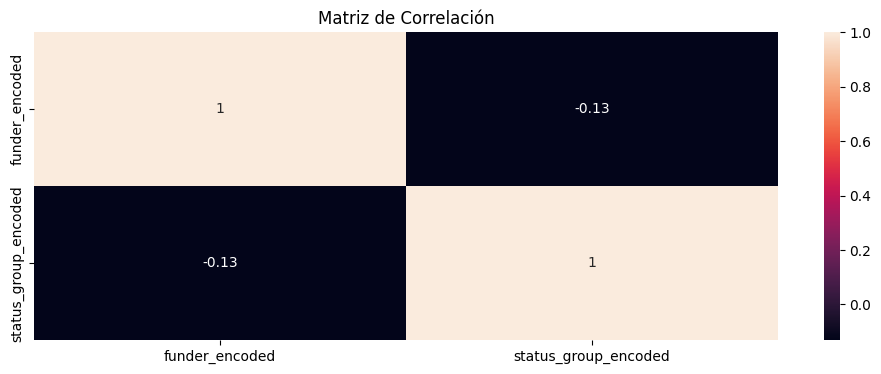

In [27]:
import matplotlib.pyplot as plt

df_funder['funder_encoded'] = df_funder['funder'].astype('category').cat.codes
df_funder['status_group_encoded'] = df_funder['status_group'].astype('category').cat.codes

plt.figure(figsize=(12, 4))
sns.heatmap(df_funder[['funder_encoded', 'status_group_encoded']].corr(), annot=True)
plt.title('Matriz de Correlación')
plt.show()

In [28]:
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import ExtraTreesClassifier

df_selected = df_funder[['funder', 'status_group']].copy()

label_encoder = LabelEncoder()
df_selected['funder_encoded'] = label_encoder.fit_transform(df_selected['funder'])
df_selected['status_group_encoded'] = label_encoder.fit_transform(df_selected['status_group'])

model = ExtraTreesClassifier()

model.fit(X=df_selected[['funder_encoded']], y=df_selected['status_group_encoded'])

feature_importances = pd.DataFrame({'Variable': ['funder'],
                                    'Importancia': model.feature_importances_})

categorias = {
    'Muy Importante': (0, 0.1),
    'Importante': (0.1, 0.2),
    'Menos Importante': (0.2, 0.3),
    'No Importante': (0.3, 1)
}

feature_importances['Categoría'] = pd.cut(feature_importances['Importancia'], bins=[0, 0.1, 0.2, 0.3, 1], labels=categorias.keys(), include_lowest=True)


for _, row in feature_importances.iterrows():
    print(f"Variable: {row['Variable']}, Importancia: {row['Importancia']:.4f}, Categoría: {row['Categoría']}")

Variable: funder, Importancia: 1.0000, Categoría: No Importante


#### Al agrupar los valores de 'funder' en categorías más generales, como 'Gobierno' y 'No gubernamental', visualmente parece que la mayoría de las bombas de agua financiadas por el Gobierno no funcionan, y que las financiadas por otros sí. Sin embargo, después de realizar un análisis exhaustivo de la variable 'funder' y utilizar diferentes técnicas estadísticas como Chi cuadrado y Correlación de Pearson, así como la técnica de selección de variables mediante Feature Importance, he llegado a la conclusión de que la variable 'funder' no es relevante para predecir la variable target 'status_group'.

## Basin

In [29]:
df_basin = df1[['basin', 'status_group']].copy()
valores_unicos_basin = df_basin['basin'].unique()
valores_unicos_basin

array(['Lake Nyasa', 'Lake Victoria', 'Pangani',
       'Ruvuma / Southern Coast', 'Internal', 'Lake Tanganyika',
       'Wami / Ruvu', 'Rufiji', 'Lake Rukwa'], dtype=object)

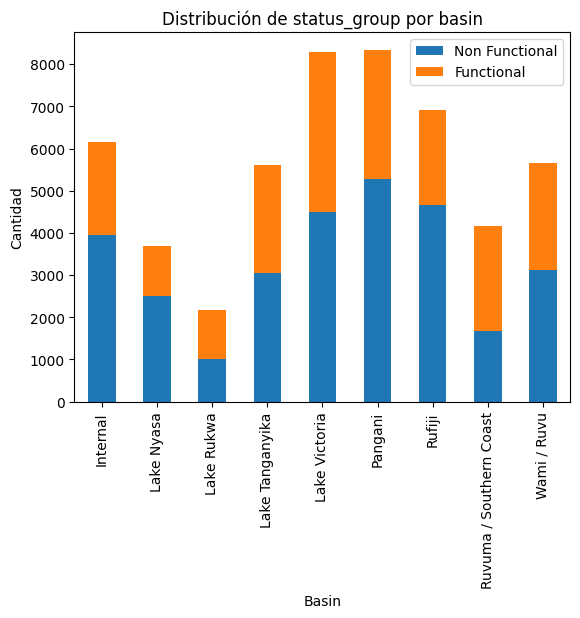

In [30]:
comparar = df1.groupby(['basin', 'status_group'])['status_group'].count().unstack()
comparar.plot(kind='bar', stacked=True)

plt.title('Distribución de status_group por basin')
plt.xlabel('Basin')
plt.ylabel('Cantidad')
plt.legend(['Non Functional', 'Functional'])
plt.show()

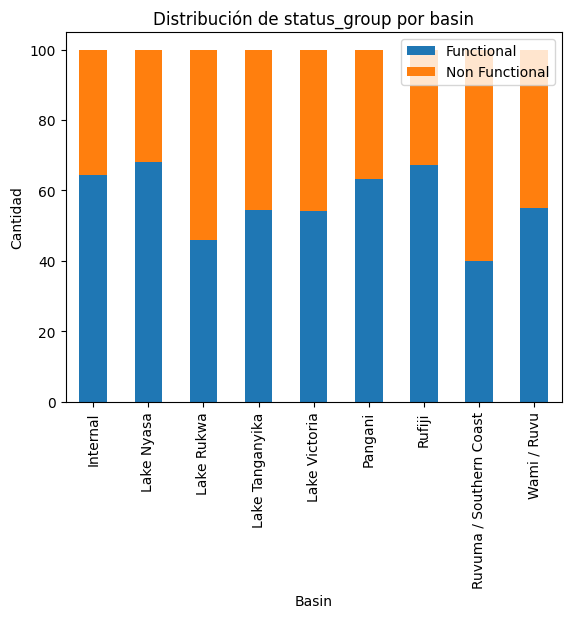

In [31]:
comparar = df1.groupby(['basin', 'status_group'])['status_group'].count().unstack()
comparar['Total'] = comparar.sum(axis=1)
comparar['Functional_Percentage'] = comparar['functional'] / comparar['Total'] * 100
comparar['Non_Functional_Percentage'] = comparar['non functional'] / comparar['Total'] * 100

comparar[['Functional_Percentage', 'Non_Functional_Percentage']].plot(kind='bar', stacked=True)

plt.title('Distribución de status_group por basin')
plt.xlabel('Basin')
plt.ylabel('Cantidad')
plt.legend(['Functional', 'Non Functional'])
plt.show()

In [32]:
df_basin_agrupado = df_basin.groupby('basin')['status_group'].value_counts(normalize=True).unstack()
df_basin_agrupado['Functional_Porcentaje'] = df_basin_agrupado['functional'] * 100

df_basin_agrupado['Condicion'] = np.where(df_basin_agrupado['Functional_Porcentaje'] >= 59, 'basin_mejor_condicion', 'basin_peor_condicion')

df_basin_agrupado = df_basin_agrupado.reset_index()

In [33]:
df_basin_agrupado

status_group,basin,functional,non functional,Functional_Porcentaje,Condicion
0,Internal,0.643497,0.356503,64.349666,basin_mejor_condicion
1,Lake Nyasa,0.679348,0.320652,67.934783,basin_mejor_condicion
2,Lake Rukwa,0.458047,0.541953,45.804677,basin_peor_condicion
3,Lake Tanganyika,0.544872,0.455128,54.487179,basin_peor_condicion
4,Lake Victoria,0.541013,0.458987,54.101327,basin_peor_condicion
5,Pangani,0.632954,0.367046,63.295386,basin_mejor_condicion
6,Rufiji,0.673416,0.326584,67.341626,basin_mejor_condicion
7,Ruvuma / Southern Coast,0.400385,0.599615,40.038452,basin_peor_condicion
8,Wami / Ruvu,0.549373,0.450627,54.937290,basin_peor_condicion


In [34]:
df_basin

,basin,status_group
0,Lake Nyasa,functional
1,Lake Victoria,functional
2,Pangani,functional
3,Ruvuma / Southern Coast,non functional
4,Lake Victoria,functional
...,...,...
55077,Wami / Ruvu,non functional
55078,Pangani,functional
55079,Rufiji,functional
55081,Rufiji,functional


In [35]:
df_basin_new = df_basin.copy()
df_basin_new['basin'] = np.where(df_basin_new['basin'].isin(df_basin_agrupado.loc[df_basin_agrupado['Condicion'] == 'basin_mejor_condicion', 'basin']), 1, 0)
df_basin_new.head(10)

,basin,status_group
0,1,functional
1,0,functional
2,1,functional
3,0,non functional
4,0,functional
5,1,functional
6,1,non functional
7,0,non functional
8,0,non functional
9,0,functional


In [36]:
valores_unicos = df_basin_new['basin'].unique()
valores_unicos

array([1, 0])

In [37]:
import scipy.stats as stats
import numpy as np

df_basin_chi = df_basin.copy()
df_basin_chi['basin'] = df_basin['basin'].astype('category')
df_basin_chi['status_group'] = df_basin['status_group'].astype('category')

CrosstabResult = pd.crosstab(df_basin['basin'], columns=df_basin['status_group'])
CrosstabPercent = pd.crosstab(df_basin['basin'], columns=df_basin['status_group'], normalize='index')
print(CrosstabPercent)

ChiSqResult = stats.chi2_contingency(CrosstabResult)
chi2_stat, pvalue, dof, expected = ChiSqResult
prob = 0.95
critical = stats.chi2.ppf(prob, df=dof)
if np.abs(chi2_stat) < critical:
    print("La variable 'basin' es dependiente de la variable target.")
    print("El valor p del test Chi2 es:", pvalue)
else:
    print("La variable 'basin' no es dependiente de la variable target.")

status_group             functional  non functional
basin                                              
Internal                   0.643497        0.356503
Lake Nyasa                 0.679348        0.320652
Lake Rukwa                 0.458047        0.541953
Lake Tanganyika            0.544872        0.455128
Lake Victoria              0.541013        0.458987
Pangani                    0.632954        0.367046
Rufiji                     0.673416        0.326584
Ruvuma / Southern Coast    0.400385        0.599615
Wami / Ruvu                0.549373        0.450627
La variable 'basin' no es dependiente de la variable target.


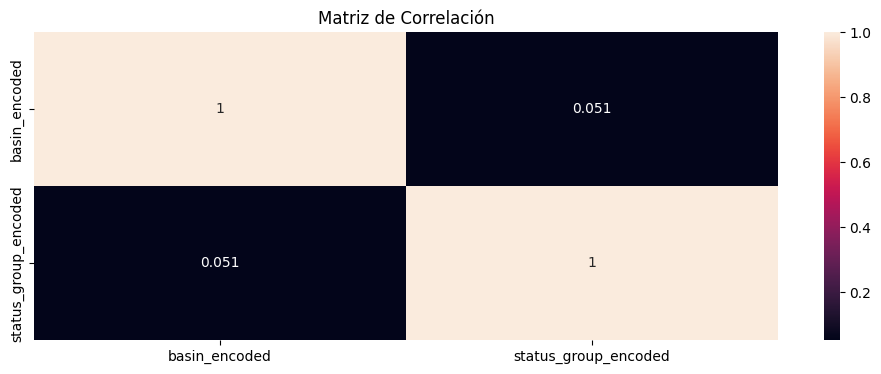

In [38]:
import matplotlib.pyplot as plt

df_basin_pearson = df_basin.copy()
df_basin_pearson['basin_encoded'] = df_basin_pearson['basin'].astype('category').cat.codes
df_basin_pearson['status_group_encoded'] = df_basin_pearson['status_group'].astype('category').cat.codes

plt.figure(figsize=(12, 4))
sns.heatmap(df_basin_pearson[['basin_encoded', 'status_group_encoded']].corr(), annot=True)
plt.title('Matriz de Correlación')
plt.show()

In [39]:
df_basin_pearson['basin_encoded']

0        1
1        4
2        5
3        7
4        4
        ..
55077    8
55078    5
55079    6
55081    6
55082    8
Name: basin_encoded, Length: 50991, dtype: int8

In [40]:
df_selected1 = df_basin[['basin', 'status_group']].copy()

label_encoder = LabelEncoder()
df_selected1['basin_encoded'] = label_encoder.fit_transform(df_selected1['basin'])
df_selected1['status_group_encoded'] = label_encoder.fit_transform(df_selected1['status_group'])

model = ExtraTreesClassifier()

model.fit(X=df_selected1[['basin_encoded']], y=df_selected1['status_group_encoded'])

feature_importances = pd.DataFrame({'Variable': ['basin'],
                                    'Importancia': model.feature_importances_})

categorias = {
    'Muy Importante': (0, 0.1),
    'Importante': (0.1, 0.2),
    'Menos Importante': (0.2, 0.3),
    'No Importante': (0.3, 1)
}

feature_importances['Categoría'] = pd.cut(feature_importances['Importancia'], bins=[0, 0.1, 0.2, 0.3, 1], labels=categorias.keys(), include_lowest=True)


for _, row in feature_importances.iterrows():
    print(f"Variable: {row['Variable']}, Importancia: {row['Importancia']:.4f}, Categoría: {row['Categoría']}")

Variable: basin, Importancia: 1.0000, Categoría: No Importante


In [41]:
df_basin_new

,basin,status_group
0,1,functional
1,0,functional
2,1,functional
3,0,non functional
4,0,functional
...,...,...
55077,0,non functional
55078,1,functional
55079,1,functional
55081,1,functional


In [42]:
import scipy.stats as stats
import numpy as np

df_basin_chi_new = df_basin_new.copy()
df_basin_chi_new['basin'] = df_basin_chi_new['basin'].astype('category')
df_basin_chi_new['status_group'] = df_basin_chi_new['status_group'].astype('category')

CrosstabResult = pd.crosstab(df_basin_chi_new['basin'], columns=df_basin_chi_new['status_group'])
CrosstabPercent = pd.crosstab(df_basin_chi_new['basin'], columns=df_basin_chi_new['status_group'], normalize='index')
print(CrosstabPercent)

ChiSqResult = stats.chi2_contingency(CrosstabResult)
chi2_stat, pvalue, dof, expected = ChiSqResult
prob = 0.95
critical = stats.chi2.ppf(prob, df=dof)
if np.abs(chi2_stat) < critical:
    print("La variable 'basin' es dependiente de la variable target.")
    print("El valor p del test Chi2 es:", pvalue)
else:
    print("La variable 'basin' no es dependiente de la variable target.")

status_group  functional  non functional
basin                                   
0               0.514107        0.485893
1               0.653497        0.346503
La variable 'basin' no es dependiente de la variable target.


In [43]:
df_basin_new.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 50991 entries, 0 to 55082
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   basin         50991 non-null  int64 
 1   status_group  50991 non-null  object
dtypes: int64(1), object(1)
memory usage: 1.2+ MB


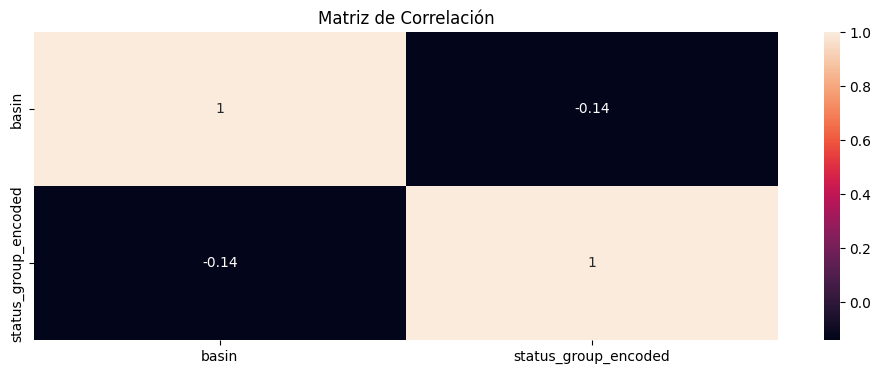

In [44]:
import matplotlib.pyplot as plt

df_basin_pearson_new = df_basin_new.copy()
#df_basin_pearson_new['basin_encoded'] = df_basin_pearson_new['basin'].astype('category').cat.codes
df_basin_pearson_new['status_group_encoded'] = df_basin_pearson_new['status_group'].astype('category').cat.codes

plt.figure(figsize=(12, 4))
sns.heatmap(df_basin_pearson_new[['basin', 'status_group_encoded']].corr(), annot=True)
plt.title('Matriz de Correlación')
plt.show()

In [45]:
df_selected2 = df_basin_new.copy()

label_encoder = LabelEncoder()
df_selected2['basin_encoded'] = label_encoder.fit_transform(df_selected2['basin'])
df_selected2['status_group_encoded'] = label_encoder.fit_transform(df_selected2['status_group'])

model = ExtraTreesClassifier()

model.fit(X=df_selected2[['basin_encoded']], y=df_selected2['status_group_encoded'])

feature_importances = pd.DataFrame({'Variable': ['basin'],
                                    'Importancia': model.feature_importances_})

categorias = {
    'Muy Importante': (0, 0.1),
    'Importante': (0.1, 0.2),
    'Menos Importante': (0.2, 0.3),
    'No Importante': (0.3, 1)
}

feature_importances['Categoría'] = pd.cut(feature_importances['Importancia'], bins=[0, 0.1, 0.2, 0.3, 1], labels=categorias.keys(), include_lowest=True)

for _, row in feature_importances.iterrows():
    print(f"Variable: {row['Variable']}, Importancia: {row['Importancia']:.4f}, Categoría: {row['Categoría']}")

Variable: basin, Importancia: 1.0000, Categoría: No Importante


#### Después de realizar un análisis exhaustivo de la variable 'basin' utilizando diferentes técnicas estadísticas como Chi cuadrado y Correlación de Pearson, así como la técnica de selección de variables mediante Feature Importance, he llegado a la conclusión de que la variable 'basin' no muestra una relación significativa con la variable objetivo 'status_group'.

#### Además, realicé una agrupación de los basins según la distribución de bombas funcionales y no funcionales, y tampoco se encontraron patrones claros que indiquen una relación entre el 'basin' y el estado de las bombas.

#### Por lo tanto, no recomiendo utilizar la variable 'basin' como predictor para la variable target ('status_group'). 

## public_meeting

#### Hay un poco mas de 5% de valores NaN

In [46]:
df_public_meeting = df1[['public_meeting', 'status_group']].copy()
valores_unicos_public_meeting = df_public_meeting['public_meeting'].unique()
valores_unicos_public_meeting

array([True, nan, False], dtype=object)

In [47]:
df_public_meeting = df_public_meeting.dropna()
df_public_meeting

,public_meeting,status_group
0,True,functional
2,True,functional
3,True,non functional
4,True,functional
5,True,functional
...,...,...
55077,True,non functional
55078,True,functional
55079,True,functional
55081,True,functional


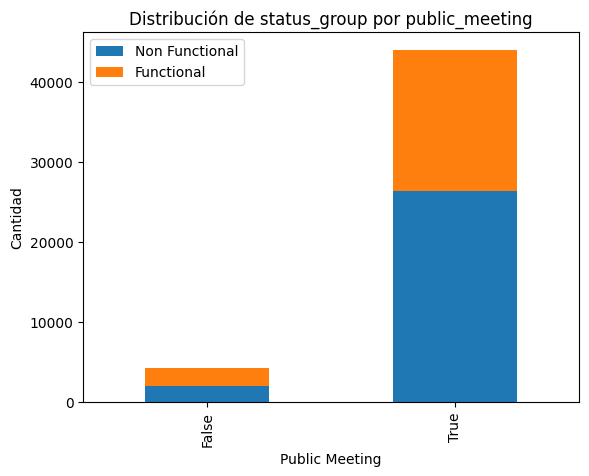

In [48]:
comparar_public = df_public_meeting.groupby(['public_meeting', 'status_group'])['status_group'].count().unstack()
comparar_public.plot(kind='bar', stacked=True)

plt.title('Distribución de status_group por public_meeting')
plt.xlabel('Public Meeting')
plt.ylabel('Cantidad')
plt.legend(['Non Functional', 'Functional'])
plt.show()

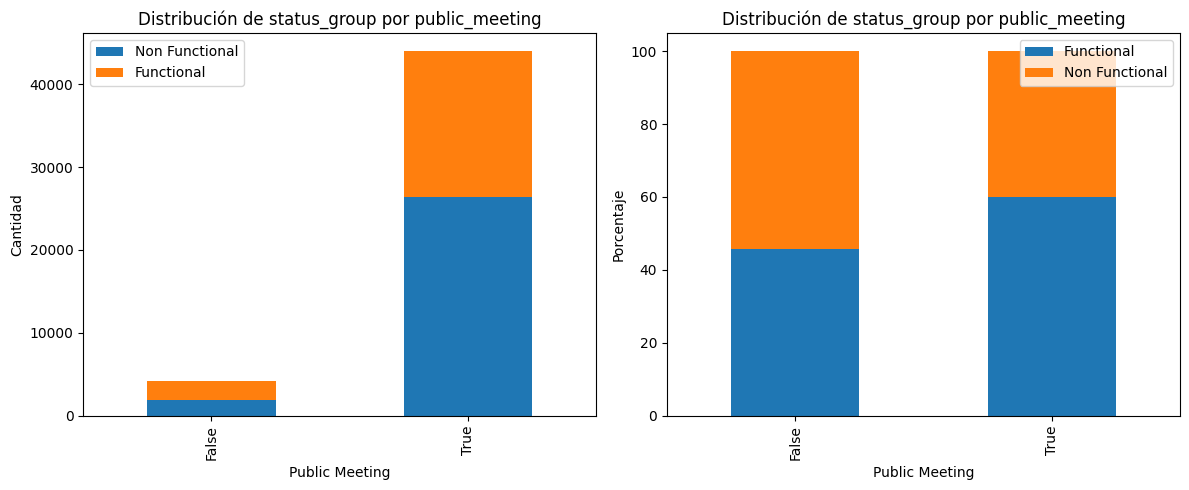

In [49]:
import matplotlib.pyplot as plt

# Gráfico 1: Distribución de status_group por public_meeting
comparar_public = df_public_meeting.groupby(['public_meeting', 'status_group'])['status_group'].count().unstack()
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))

comparar_public.plot(kind='bar', stacked=True, ax=axes[0])
axes[0].set_title('Distribución de status_group por public_meeting')
axes[0].set_xlabel('Public Meeting')
axes[0].set_ylabel('Cantidad')
axes[0].legend(['Non Functional', 'Functional'])

# Gráfico 2: Distribución de status_group por public_meeting
comparar = df_public_meeting.groupby(['public_meeting', 'status_group'])['status_group'].count().unstack()
comparar['Total'] = comparar.sum(axis=1)
comparar['Functional_Porcentaje'] = comparar['functional'] / comparar['Total'] * 100
comparar['Non_Functional_Porcentaje'] = comparar['non functional'] / comparar['Total'] * 100

comparar[['Functional_Porcentaje', 'Non_Functional_Porcentaje']].plot(kind='bar', stacked=True, ax=axes[1])
axes[1].set_title('Distribución de status_group por public_meeting')
axes[1].set_xlabel('Public Meeting')
axes[1].set_ylabel('Porcentaje')
axes[1].legend(['Functional', 'Non Functional'])

plt.tight_layout()
plt.show()

####  Según la visualización del gráfico, se puede apreciar que cuando el valor de la variable 'public_meeting' es True, hay más bombas en funcionamiento en comparación con cuando el valor es False. Esto indica que la variable 'public_meeting' puede ser un factor relevante para determinar si una bomba está funcionando correctamente.

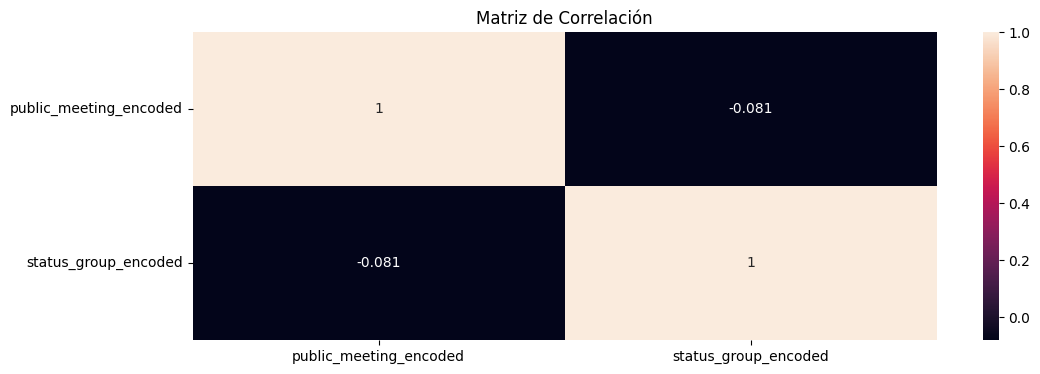

In [50]:
df_public_meeting_pearson = df_public_meeting.copy()
df_public_meeting_pearson['public_meeting_encoded'] = df_public_meeting_pearson['public_meeting'].astype('category').cat.codes
df_public_meeting_pearson['status_group_encoded'] = df_public_meeting_pearson['status_group'].astype('category').cat.codes

plt.figure(figsize=(12, 4))
sns.heatmap(df_public_meeting_pearson[['public_meeting_encoded', 'status_group_encoded']].corr(), annot=True)
plt.title('Matriz de Correlación')
plt.show()

In [51]:
df_public_meeting_pearson['public_meeting_encoded'].unique()

array([1, 0], dtype=int8)

In [52]:
df_public_meeting_pearson['status_group_encoded'].unique()

array([0, 1], dtype=int8)

In [53]:
import scipy.stats as stats
import numpy as np

df_public_meeting_chi = df_public_meeting.copy()
df_public_meeting_chi['public_meeting'] = df_public_meeting_chi['public_meeting'].astype('category')
df_public_meeting_chi['status_group'] = df_public_meeting_chi['status_group'].astype('category')

CrosstabResult = pd.crosstab(df_public_meeting_chi['public_meeting'], columns=df_public_meeting_chi['status_group'])
CrosstabPercent = pd.crosstab(df_public_meeting_chi['public_meeting'], columns=df_public_meeting_chi['status_group'], normalize='index')
print(CrosstabPercent)

ChiSqResult = stats.chi2_contingency(CrosstabResult)
chi2_stat, pvalue, dof, expected = ChiSqResult
prob = 0.95
critical = stats.chi2.ppf(prob, df=dof)
if np.abs(chi2_stat) < critical:
    print("La variable 'public_meeting' es dependiente de la variable target.")
    print("El valor p del test Chi2 es:", pvalue)
else:
    print("La variable 'public_meeting' no es dependiente de la variable target.")

status_group    functional  non functional
public_meeting                            
False             0.458539        0.541461
True              0.599304        0.400696
La variable 'public_meeting' no es dependiente de la variable target.


In [54]:
import scipy.stats as stats


variables = ["funder", "public_meeting", "basin"]

for i in variables:
    crosstab_result = pd.crosstab(index=df1[i], columns=df1["status_group"])
    crosstab_percent = pd.crosstab(index=df1[i], columns=df1["status_group"], normalize="index")
    
    chi2_stat, pvalue, dof, _ = stats.chi2_contingency(crosstab_result)
    prob = 0.95
    critical = stats.chi2.ppf(prob, df=dof)
    
    if np.abs(chi2_stat) < critical:
        print(f"La variable '{i}' es buena.")
        print("El p-valor del test Chi2 es:", pvalue)
    else:
        print(f"La variable '{i}' no es buena.")

La variable 'funder' no es buena.
La variable 'public_meeting' no es buena.
La variable 'basin' no es buena.


In [55]:
df2 = df1.copy()

variables = ["funder", "public_meeting", "basin"]

for variable in variables:
    df2[variable] = df2[variable].astype('category')

for i in variables:
    crosstab_result = pd.crosstab(index=df2[i], columns=df2["status_group"])
    crosstab_percent = pd.crosstab(index=df2[i], columns=df2["status_group"], normalize="index")
    
    chi2_stat, pvalue, dof, _ = stats.chi2_contingency(crosstab_result)
    prob = 0.95
    critical = stats.chi2.ppf(prob, df=dof)
    
    if np.abs(chi2_stat) < critical:
        print(f"La variable '{i}' es buena.")
        print("El p-valor del test Chi2 es:", pvalue)
    else:
        print(f"La variable '{i}' no es buena.")

La variable 'funder' no es buena.


La variable 'public_meeting' no es buena.
La variable 'basin' no es buena.


#### Según el resultado del análisis, podemos concluir que la variable 'public_meeting' tampoco es relevante en relación a nuestra variable objetivo (status_group). Esto se determinó utilizando las mismas técnicas estadísticas aplicadas previamente.

## management_group

In [56]:
df_management_group = df1[['management_group', 'status_group']].copy()
valores_unicos_management_group = df_management_group['management_group'].unique()
valores_unicos_management_group

array(['user-group', 'other', 'commercial', 'parastatal', 'unknown'],
      dtype=object)

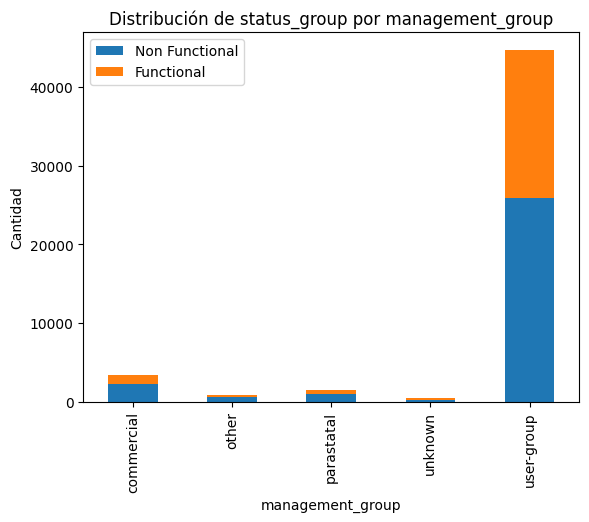

In [57]:
comparar_management_group = df_management_group.groupby(['management_group', 'status_group'])['status_group'].count().unstack()
comparar_management_group.plot(kind='bar', stacked=True)

plt.title('Distribución de status_group por management_group')
plt.xlabel('management_group')
plt.ylabel('Cantidad')
plt.legend(['Non Functional', 'Functional'])
plt.show()

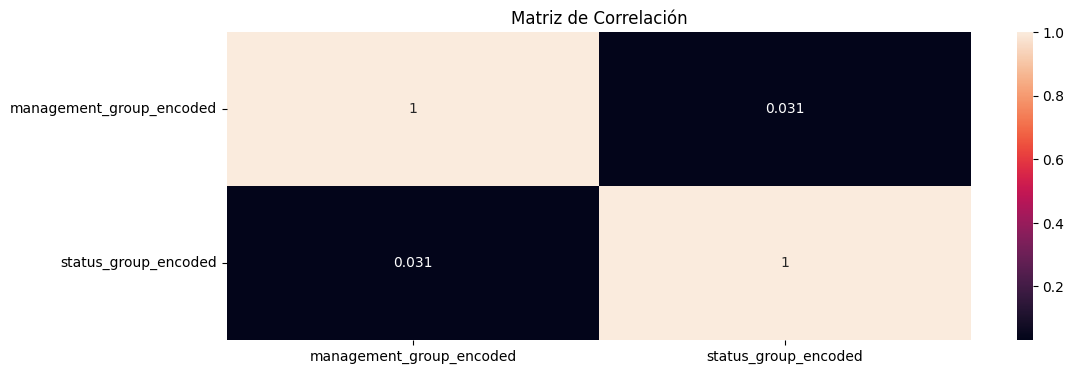

In [58]:
df_management_group_pearson = df_management_group.copy()
df_management_group_pearson['management_group_encoded'] = df_management_group_pearson['management_group'].astype('category').cat.codes
df_management_group_pearson['status_group_encoded'] = df_management_group_pearson['status_group'].astype('category').cat.codes

plt.figure(figsize=(12, 4))
sns.heatmap(df_management_group_pearson[['management_group_encoded', 'status_group_encoded']].corr(), annot=True)
plt.title('Matriz de Correlación')
plt.show()

In [59]:
df_management_group_pearson

,management_group,status_group,management_group_encoded,status_group_encoded
0,user-group,functional,4,0
1,user-group,functional,4,0
2,user-group,functional,4,0
3,user-group,non functional,4,1
4,other,functional,1,0
...,...,...,...,...
55077,user-group,non functional,4,1
55078,user-group,functional,4,0
55079,user-group,functional,4,0
55081,user-group,functional,4,0


In [60]:
unique_values = df_management_group_pearson['management_group_encoded'].unique()
print(unique_values)

[4 1 0 2 3]


In [61]:
value_counts = df_management_group_pearson['management_group_encoded'].value_counts()
print(value_counts)

4    44762
0     3419
2     1422
1      881
3      507
Name: management_group_encoded, dtype: int64


#### Apliqué los mismos criterios y otros adicionales, y llegué a la conclusión de que la variable 'management_group' no es buena para predecir.

# Aplicando SelectKBest
[https://www.dataknowsall.com/featureselection.html]

In [62]:
df_prob = df1[['funder', 'basin', 'public_meeting', 'management_group', 'status_group']].copy()
df_prob

,funder,basin,public_meeting,management_group,status_group
0,No gubernamental,Lake Nyasa,True,user-group,functional
1,No gubernamental,Lake Victoria,NaN,user-group,functional
2,No gubernamental,Pangani,True,user-group,functional
3,No gubernamental,Ruvuma / Southern Coast,True,user-group,non functional
4,No gubernamental,Lake Victoria,True,other,functional
...,...,...,...,...,...
55077,No gubernamental,Wami / Ruvu,True,user-group,non functional
55078,No gubernamental,Pangani,True,user-group,functional
55079,No gubernamental,Rufiji,True,user-group,functional
55081,No gubernamental,Rufiji,True,user-group,functional


In [63]:
df_prob_sin_nan = df_prob.dropna()

In [64]:
df_prob_sin_nan

,funder,basin,public_meeting,management_group,status_group
0,No gubernamental,Lake Nyasa,True,user-group,functional
2,No gubernamental,Pangani,True,user-group,functional
3,No gubernamental,Ruvuma / Southern Coast,True,user-group,non functional
4,No gubernamental,Lake Victoria,True,other,functional
5,No gubernamental,Pangani,True,user-group,functional
...,...,...,...,...,...
55077,No gubernamental,Wami / Ruvu,True,user-group,non functional
55078,No gubernamental,Pangani,True,user-group,functional
55079,No gubernamental,Rufiji,True,user-group,functional
55081,No gubernamental,Rufiji,True,user-group,functional


In [65]:
df_prob_sin_nan.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 48243 entries, 0 to 55082
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   funder            48243 non-null  object
 1   basin             48243 non-null  object
 2   public_meeting    48243 non-null  object
 3   management_group  48243 non-null  object
 4   status_group      48243 non-null  object
dtypes: object(5)
memory usage: 2.2+ MB


In [66]:
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.preprocessing import LabelEncoder

df_prob = df_prob_sin_nan.astype('category')

In [67]:
label_encoder = LabelEncoder()

for column in df_prob.columns:
    df_prob[column] = label_encoder.fit_transform(df_prob[column])

X = df_prob.loc[:, df_prob.columns != 'status_group']
y = df_prob['status_group']

selector_var = SelectKBest(score_func=chi2, k=4)
selector_var.fit_transform(X, y)

feature_names = X.columns[selector_var.get_support()]

print(feature_names)

Index(['funder', 'basin', 'public_meeting', 'management_group'], dtype='object')


In [68]:
# Puntuación chi2 de cada variable
for nombre, puntuacion in zip(X.columns, selector_var.scores_):
    print('{}: {:.2f}'.format(nombre, puntuacion))

funder: 140.50
basin: 231.74
public_meeting: 27.99
management_group: 2.02


#### Después de evaluar todas las variables utilizando la técnica de selección de variables SelectKBest, llegué a la conclusión de que todas las variables: 'funder', 'basin', 'public_meeting' y 'management_group', pueden ser relevantes para predecir la variable objetivo ('status_group'). El orden de importancia de estas variables, comenzando desde la más importante, es el siguiente: 'funder', 'basin', 'public_meeting', 'management_group'.

In [69]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 54187 entries, 0 to 55082
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   amount_tsh             54187 non-null  float64
 1   funder                 50991 non-null  object 
 2   gps_height             54187 non-null  int64  
 3   installer              50974 non-null  object 
 4   longitude              54187 non-null  float64
 5   latitude               54187 non-null  float64
 6   basin                  54187 non-null  object 
 7   region                 54187 non-null  object 
 8   population             54187 non-null  int64  
 9   public_meeting         51250 non-null  object 
 10  scheme_management      50576 non-null  object 
 11  permit                 51431 non-null  object 
 12  construction_year      54187 non-null  int64  
 13  extraction_type        54187 non-null  object 
 14  management_group       54187 non-null  object 
 15  pa

In [70]:
# valores_frecuencia = df1["installer"].value_counts() 
# valores_frecuencia.head(40)

In [71]:
# cantidad_valores_unicos = df1['installer'].nunique()
# cantidad_valores_unicos

In [72]:
# fun_ins = df[['funder', 'installer']]
# fun_ins.head(41)

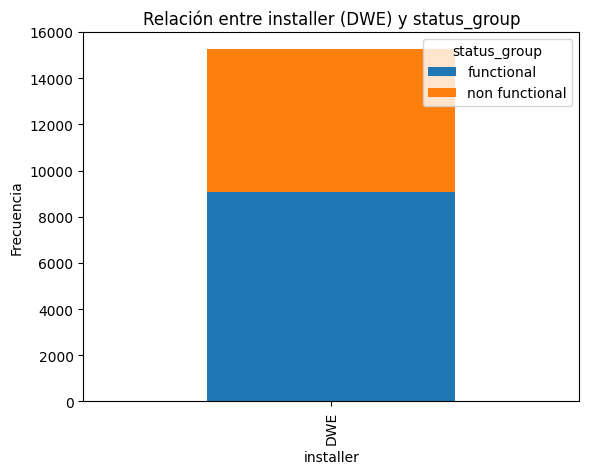

In [73]:
df_dwe = df[df['installer'] == 'DWE']

tabla_contingencia = pd.crosstab(df_dwe['installer'], df_dwe['status_group'])

tabla_contingencia.plot.bar(stacked=True)

plt.xlabel('installer')
plt.ylabel('Frecuencia')
plt.title('Relación entre installer (DWE) y status_group')
plt.legend(title='status_group')

plt.show()

### Las variables 'funder' y 'installer' pueden ser eliminadas debido a la alta cantidad de valores únicos (funder - 1854, installer - 2088) y a la falta de una relación clara y significativa con la variable objetivo ('status_group'). Al agrupar los valores de 'funder' en categorías más generales, como 'Gobierno' y 'Otros', visualmente parece que la mayoría de las bombas de agua financiadas por el Gobierno no funcionan, y que las financiadas por otros sí. Sin embargo, esta afirmación se excluye después de comparar 'funder' y 'installer'. En esta comparación se observa que en muchos casos el financiador y el instalador suelen ser la misma entidad. Además, cuando no son iguales, suele aparecer 'DWE' como instalador. 'DWE' corresponde a las siglas de Distrito de Ingeniería de Agua (District Water Engineer), que forma parte de los equipos de facilitación y supervisión del gobierno en la implementación de proyectos de agua. Otras categorías principales de instaladores, como 'Central government', 'District council' y 'DWSP' (District Water and Sanitation Plans), entre otros, también respaldan la conclusión de que, independientemente de la fuente de financiamiento, es el Gobierno quien principalmente encarga y supervisa estas instalaciones. Otra observación importante es que donde hay valores nulos en la variable 'funder', también existen valores nulos en la variable 'installer'. Esto indica que cuando falta información sobre el financiador, también falta información sobre el instalador, como se puede ver en el caso del valor 'Not Known' (funder - Not Known, installer - Not Known).

In [74]:
df = df.drop(['funder', 'installer'], axis=1)
df.columns

Index(['amount_tsh', 'gps_height', 'longitude', 'latitude', 'basin', 'region',
       'population', 'public_meeting', 'scheme_management', 'permit',
       'construction_year', 'extraction_type', 'management_group',
       'payment_type', 'water_quality', 'quality_group', 'quantity_group',
       'source_class', 'waterpoint_type_group', 'status_group'],
      dtype='object')

In [75]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 54187 entries, 0 to 55082
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   amount_tsh             54187 non-null  float64
 1   gps_height             54187 non-null  int64  
 2   longitude              54187 non-null  float64
 3   latitude               54187 non-null  float64
 4   basin                  54187 non-null  object 
 5   region                 54187 non-null  object 
 6   population             54187 non-null  int64  
 7   public_meeting         51250 non-null  object 
 8   scheme_management      50576 non-null  object 
 9   permit                 51431 non-null  object 
 10  construction_year      54187 non-null  int64  
 11  extraction_type        54187 non-null  object 
 12  management_group       54187 non-null  object 
 13  payment_type           54187 non-null  object 
 14  water_quality          54187 non-null  object 
 15  qu

In [76]:
valores_frecuencia = df["gps_height"].value_counts() 
valores_frecuencia.head(40)

 0       17799
-15         59
-13         54
-16         51
-20         51
-14         51
-18         48
 1290       48
-19         47
 303        47
-23         44
 1286       43
 1269       43
-8          42
-17         42
 1304       42
-6          41
-11         41
 1295       41
 12         41
 1401       41
 1303       40
 1317       40
 1538       40
 1288       40
 320        40
 1152       40
 1311       40
 1293       40
 1613       40
-2          40
 309        40
 336        40
-21         39
 1332       39
 1264       39
 338        38
 1323       38
 280        38
 1322       38
Name: gps_height, dtype: int64

In [77]:
gps_height_cero = df.loc[df['gps_height'] == 0, 'basin'].unique()
print(gps_height_cero)

['Lake Victoria' 'Pangani' 'Internal' 'Lake Tanganyika' 'Wami / Ruvu'
 'Lake Nyasa' 'Rufiji' 'Lake Rukwa' 'Ruvuma / Southern Coast']


In [78]:
gps_lon_lat = df[['gps_height', 'longitude', 'latitude']]
gps_lon_lat.head(20)

,gps_height,longitude,latitude
0,1390,34.938093,-9.856322
1,1399,34.698766,-2.147466
2,686,37.460664,-3.821329
3,263,38.486161,-11.155298
4,0,31.130847,-1.825359
5,0,39.172796,-4.765587
6,0,33.362410,-3.766365
7,0,32.620617,-4.226198
8,0,32.711100,-5.146712
9,0,30.626991,-1.257051


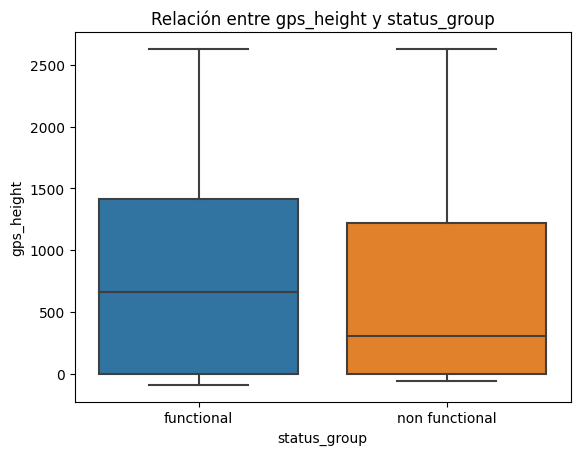

In [79]:
import seaborn as sns

sns.boxplot(x='status_group', y='gps_height', data=df)
plt.xlabel('status_group')
plt.ylabel('gps_height')
plt.title('Relación entre gps_height y status_group')
plt.show()

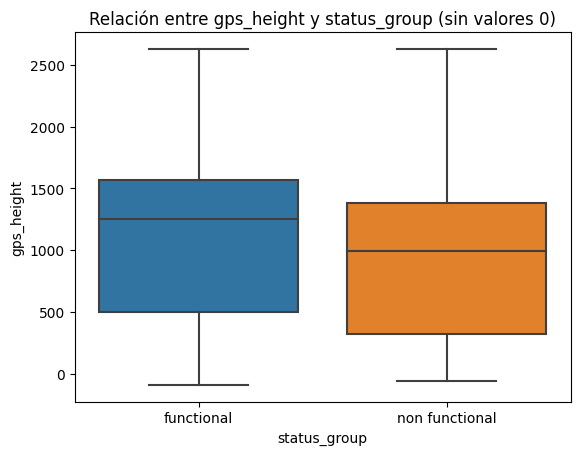

In [80]:
df_sin_ceros = df[df['gps_height'] != 0]

sns.boxplot(x='status_group', y='gps_height', data=df_sin_ceros)
plt.xlabel('status_group')
plt.ylabel('gps_height')
plt.title('Relación entre gps_height y status_group (sin valores 0)')
plt.show()

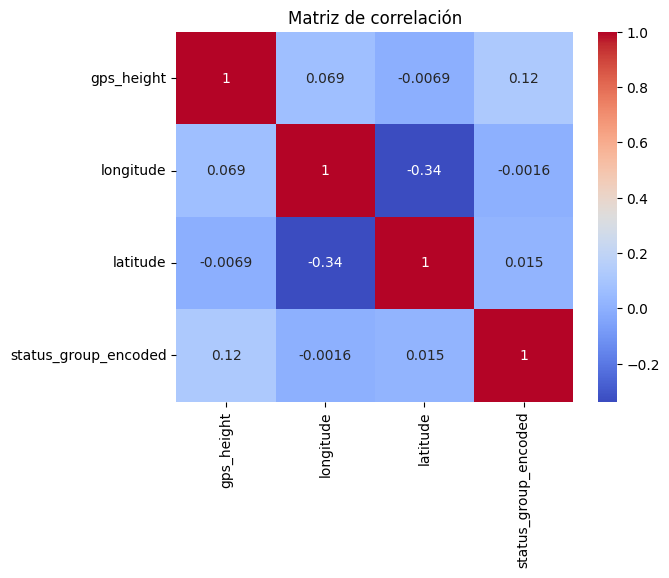

In [81]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

df['status_group_encoded'] = label_encoder.fit_transform(df['status_group'].map({'functional': 1, 'non functional': 0}))

correlation_matrix = df[['gps_height', 'longitude', 'latitude', 'status_group_encoded']].corr()

sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Matriz de correlación')
plt.show()

#df.drop('status_group_encoded', axis=1, inplace=True)

In [82]:
df['status_group_encoded'].value_counts()

1    31690
0    22497
Name: status_group_encoded, dtype: int64

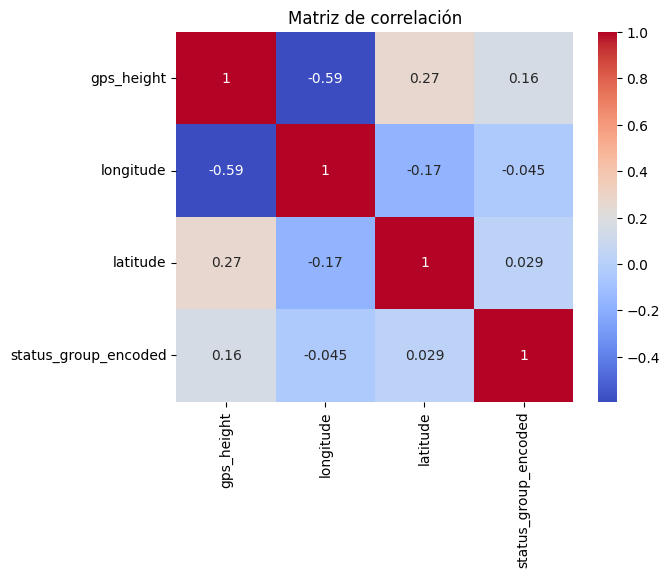

In [83]:
df_sin_ceros['status_group_encoded'] = label_encoder.fit_transform(df_sin_ceros['status_group'].map({'functional': 1, 'non functional': 0}))

correlation_matrix = df_sin_ceros[['gps_height', 'longitude', 'latitude', 'status_group_encoded']].corr()

sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Matriz de correlación')
plt.show()

In [84]:
df.columns

Index(['amount_tsh', 'gps_height', 'longitude', 'latitude', 'basin', 'region',
       'population', 'public_meeting', 'scheme_management', 'permit',
       'construction_year', 'extraction_type', 'management_group',
       'payment_type', 'water_quality', 'quality_group', 'quantity_group',
       'source_class', 'waterpoint_type_group', 'status_group',
       'status_group_encoded'],
      dtype='object')

In [85]:
import folium

mapa = folium.Map(location=[df['latitude'].mean(), df['longitude'].mean()], zoom_start=6)

for index, row in df.iterrows():

    lat = row['latitude']
    lon = row['longitude']
    status = row['status_group']
    
    if status == 'functional':
        color = 'green'
    else:
        color = 'red'
    
    folium.CircleMarker(location=[lat, lon], radius=5, color=color, fill=True, fill_color=color).add_to(mapa)

mapa

<folium.folium.Map> (mapa interactivo con 55.083 marcadores; se genera en docs/mapa_bombas.html con src/generar_mapa.py)

In [86]:
Q1 = np.quantile(df["longitude"], 0.25) 
Q3 = np.quantile(df["longitude"], 0.75) 
IQR = Q3 - Q1 

limite_inf = Q1 - 1.5 * IQR 
limite_sup = Q3 + 1.5 * IQR 

outliers_longitude = df[(df["longitude"] < limite_inf) | (df["longitude"] > limite_sup)]
outliers_longitude[['longitude', 'basin' ]].head(20)

,longitude,basin
20,0.0,Lake Victoria
47,0.0,Lake Victoria
153,0.0,Lake Victoria
162,0.0,Lake Victoria
230,0.0,Lake Victoria
256,0.0,Lake Victoria
272,0.0,Lake Victoria
277,0.0,Lake Victoria
289,0.0,Lake Victoria
292,0.0,Lake Victoria


In [87]:
print(outliers_longitude.shape)

(551, 21)


In [88]:
valores_frecuencia = df1["basin"].value_counts() 
valores_frecuencia

Pangani                    8345
Lake Victoria              8290
Rufiji                     6914
Internal                   6143
Wami / Ruvu                5661
Lake Tanganyika            5616
Ruvuma / Southern Coast    4161
Lake Nyasa                 3680
Lake Rukwa                 2181
Name: basin, dtype: int64

In [89]:
outliers_longitude['basin'].unique()

array(['Lake Victoria', 'Lake Tanganyika'], dtype=object)

In [90]:
median_longitude_lake_victoria = df.loc[df['basin'] == 'Lake Victoria', 'longitude'].median()
median_longitude_lake_tanganyika = df.loc[df['basin'] == 'Lake Tanganyika', 'longitude'].median()
print(median_longitude_lake_victoria)
print(median_longitude_lake_tanganyika)

32.98957441
31.22363833


In [91]:
df2 = df.copy()
df2.loc[df2.index.isin(outliers_longitude.index) & (df2['basin'] == 'Lake Victoria'), 'longitude'] = median_longitude_lake_victoria
df2.loc[df2.index.isin(outliers_longitude.index) & (df2['basin'] == 'Lake Tanganyika'), 'longitude'] = median_longitude_lake_tanganyika

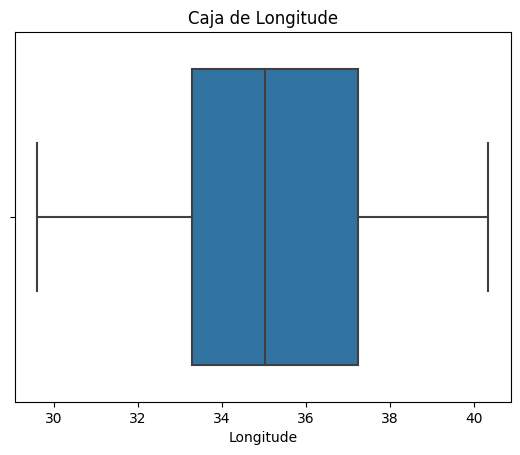

In [92]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x=df2['longitude'])
plt.title('Caja de Longitude')
plt.xlabel('Longitude')
plt.show()

In [93]:
valores_unicos_basin = df2['basin'].unique()
valores_unicos_basin

array(['Lake Nyasa', 'Lake Victoria', 'Pangani',
       'Ruvuma / Southern Coast', 'Internal', 'Lake Tanganyika',
       'Wami / Ruvu', 'Rufiji', 'Lake Rukwa'], dtype=object)

In [94]:
valores_unicos_region = df2['region'].unique()
valores_unicos_region

array(['Iringa', 'Mara', 'Manyara', 'Mtwara', 'Kagera', 'Tanga',
       'Shinyanga', 'Tabora', 'Pwani', 'Ruvuma', 'Kilimanjaro', 'Rukwa',
       'Kigoma', 'Lindi', 'Dodoma', 'Arusha', 'Mbeya', 'Singida',
       'Mwanza', 'Morogoro', 'Dar es Salaam'], dtype=object)

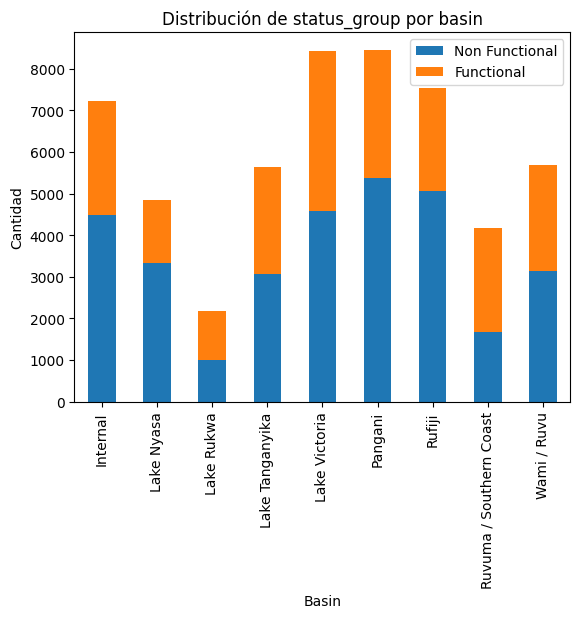

In [95]:
comparar = df.groupby(['basin', 'status_group'])['status_group'].count().unstack()
comparar.plot(kind='bar', stacked=True)

plt.title('Distribución de status_group por basin')
plt.xlabel('Basin')
plt.ylabel('Cantidad')
plt.legend(['Non Functional', 'Functional'])

In [96]:
import scipy.stats as stats

df2['basin'] = df2['basin'].astype('category')

crosstab_result = pd.crosstab(index=df2['basin'], columns=df2['status_group_encoded'])
crosstab_percent = pd.crosstab(index=df2['basin'], columns=df2['status_group_encoded'], normalize='index')

chi2_stat, pvalue, dof, _ = stats.chi2_contingency(crosstab_result)
prob = 0.1 #prob = 0.95
critical = stats.chi2.ppf(prob, df=dof)

if np.abs(chi2_stat) < critical:
    print("La variable 'basin' está relacionada con 'status_group_encoded'.")
    print("El p-valor del test Chi2 es:", pvalue)
else:
    print("La variable 'basin' no está relacionada con 'status_group_encoded'.")

La variable 'basin' no está relacionada con 'status_group_encoded'.


In [97]:
import scipy.stats as stats

df2['basin'] = df2['basin'].astype('category')

crosstab_result = pd.crosstab(index=df2['basin'], columns=df2['status_group_encoded'])
crosstab_percent = pd.crosstab(index=df2['basin'], columns=df2['status_group_encoded'], normalize='index')

chi2_stat, pvalue, dof, _ = stats.chi2_contingency(crosstab_result)
prob = 0.1 #prob = 0.95
critical = stats.chi2.ppf(prob, df=dof)

if np.abs(chi2_stat) < critical:
    print("La variable 'basin' está relacionada con 'status_group_encoded'.")
    print("El p-valor del test Chi2 es:", pvalue)
else:
    print("La variable 'basin' no está relacionada con 'status_group_encoded'.")

La variable 'basin' no está relacionada con 'status_group_encoded'.


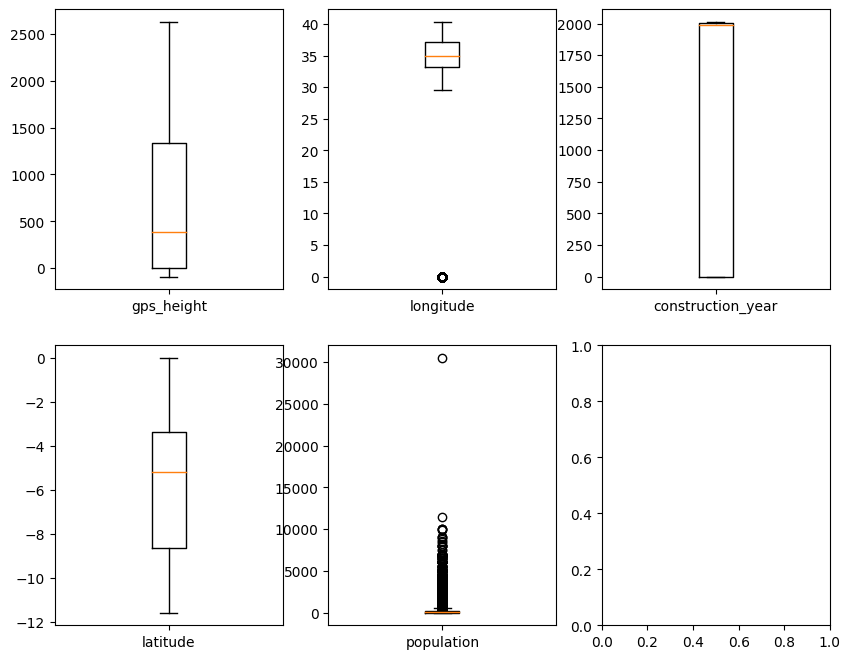

In [98]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(2, 3, figsize=(10, 8))  

col1 = ["gps_height"]
axs[0, 0].boxplot(df[col1].values)  
axs[0, 0].set_xticklabels(col1)  

col2 = ["longitude"]
axs[0, 1].boxplot(df[col2].values)  
axs[0, 1].set_xticklabels(col2)  

col3 = ["latitude"]
axs[1, 0].boxplot(df[col3].values)  
axs[1, 0].set_xticklabels(col3)  

col4 = ["population"]
axs[1, 1].boxplot(df[col4].values)  
axs[1, 1].set_xticklabels(col4)

col5 = ["construction_year"]
axs[0, 2].boxplot(df[col5].values)  
axs[0, 2].set_xticklabels(col5)

plt.show()

In [99]:
nulos = df[df['longitude']==0]
nulos

,amount_tsh,gps_height,longitude,latitude,basin,region,population,public_meeting,scheme_management,permit,construction_year,extraction_type,management_group,payment_type,water_quality,quality_group,quantity_group,source_class,waterpoint_type_group,status_group,status_group_encoded
20,0.0,0,0.0,-2.000000e-08,Lake Victoria,Shinyanga,0,NaN,WUG,False,0,swn 80,user-group,unknown,unknown,unknown,unknown,groundwater,hand pump,functional,1
47,0.0,0,0.0,-2.000000e-08,Lake Victoria,Mwanza,0,True,VWC,True,0,submersible,user-group,unknown,unknown,unknown,dry,groundwater,communal standpipe,non functional,0
153,0.0,0,0.0,-2.000000e-08,Lake Victoria,Shinyanga,0,False,Parastatal,False,0,gravity,parastatal,other,soft,good,seasonal,surface,communal standpipe,functional,1
162,0.0,0,0.0,-2.000000e-08,Lake Victoria,Shinyanga,0,NaN,WUG,False,0,other,user-group,unknown,soft,good,enough,groundwater,other,non functional,0
230,0.0,0,0.0,-2.000000e-08,Lake Victoria,Mwanza,0,True,VWC,True,0,swn 80,user-group,never pay,unknown,unknown,dry,groundwater,hand pump,non functional,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
53817,0.0,0,0.0,-2.000000e-08,Lake Victoria,Mwanza,0,True,VWC,True,0,nira/tanira,user-group,never pay,soft,good,enough,groundwater,hand pump,non functional,0
53848,0.0,0,0.0,-2.000000e-08,Lake Victoria,Shinyanga,0,False,WUG,False,0,other,user-group,never pay,soft,good,enough,groundwater,other,non functional,0
54201,0.0,0,0.0,-2.000000e-08,Lake Victoria,Mwanza,0,True,VWC,True,0,other,user-group,unknown,unknown,unknown,dry,groundwater,other,non functional,0
54292,0.0,0,0.0,-2.000000e-08,Lake Victoria,Mwanza,0,True,VWC,True,0,other,user-group,unknown,unknown,unknown,dry,groundwater,other,non functional,0


<Axes: xlabel='waterpoint_type_group', ylabel='gps_height'>

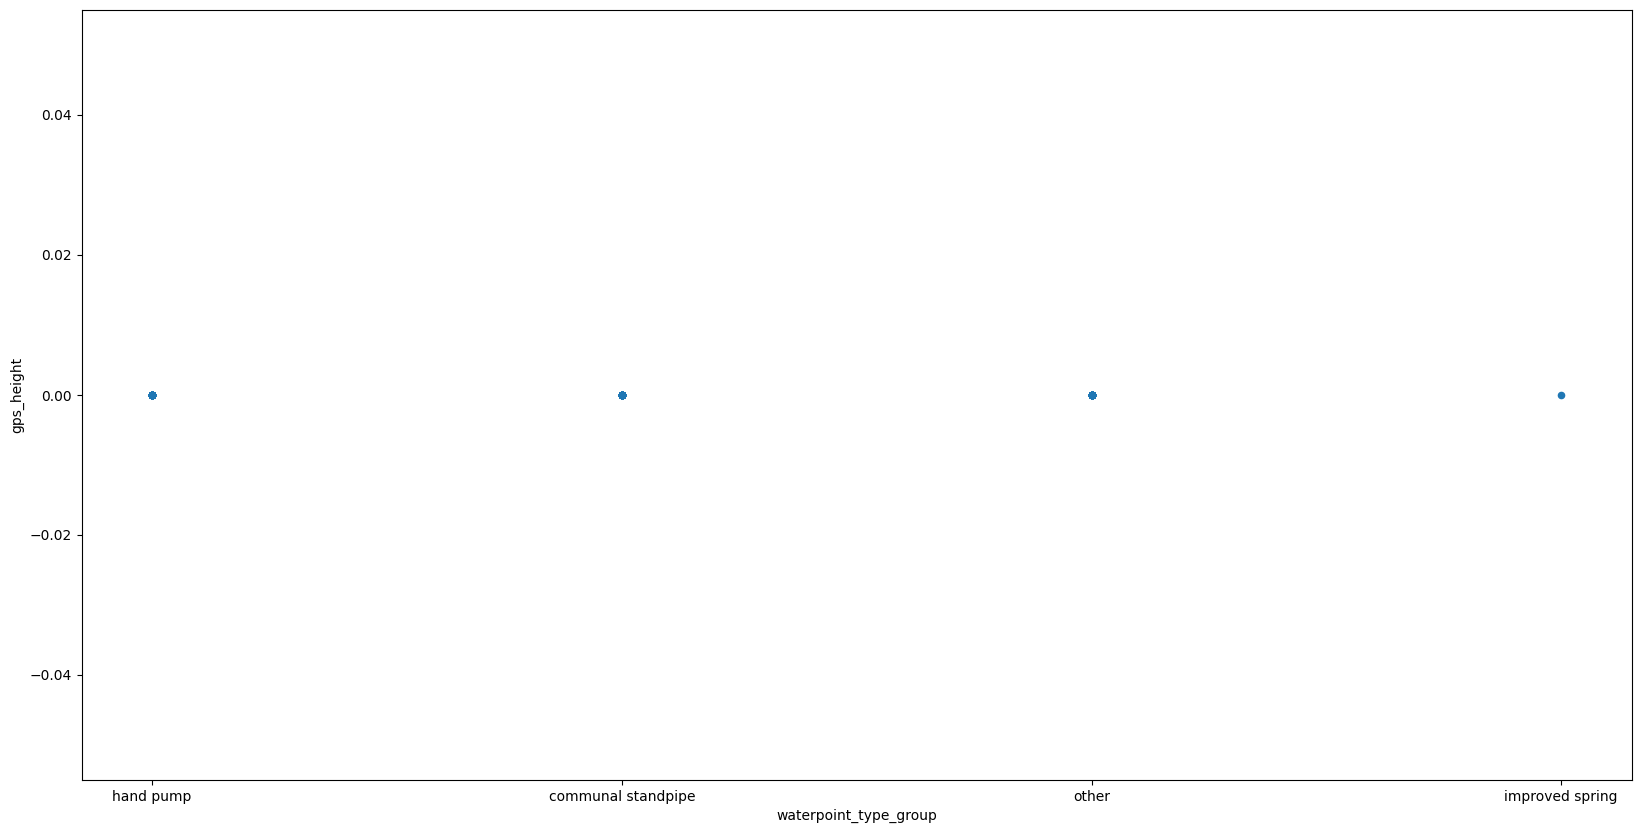

In [100]:
import matplotlib.pyplot as plt

nulos[['waterpoint_type_group', 'gps_height']].plot(x='waterpoint_type_group', y='gps_height', kind='scatter', figsize=(20,10))

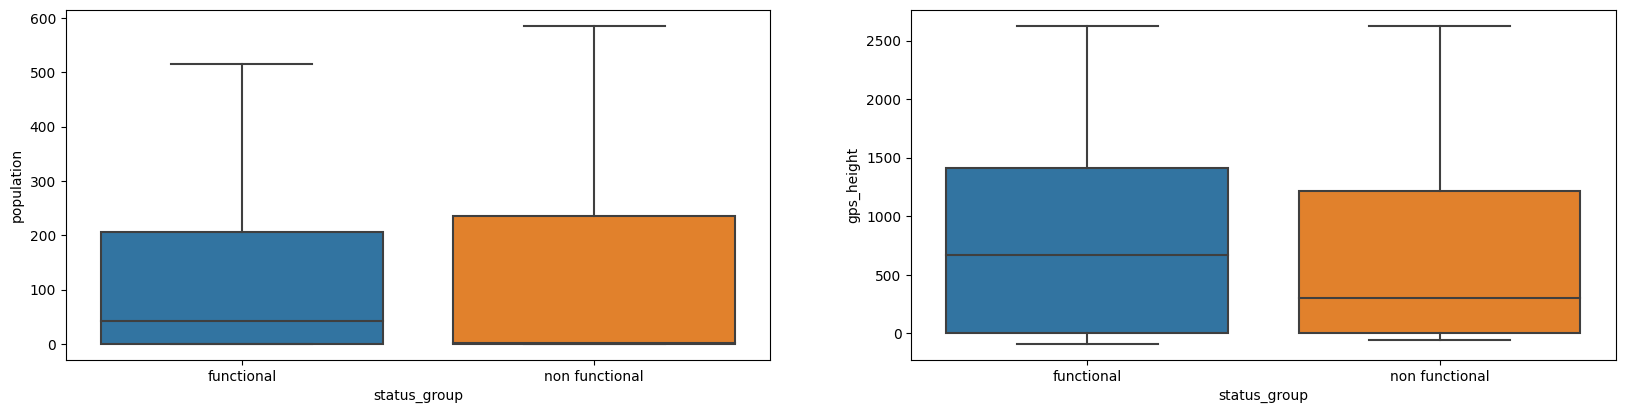

In [101]:
import matplotlib.pyplot as plt
import seaborn as sns

datos_features = df[['population', 'gps_height']]
fig = plt.figure(figsize=(20,10))

for i, column in enumerate(datos_features.columns):
    fig.add_subplot(2, 2, i+1)
    sns.boxplot(x = df['status_group'], y = df[column], showfliers = False)
    plt.xlabel(f'status_group')

In [102]:
nulos

,amount_tsh,gps_height,longitude,latitude,basin,region,population,public_meeting,scheme_management,permit,construction_year,extraction_type,management_group,payment_type,water_quality,quality_group,quantity_group,source_class,waterpoint_type_group,status_group,status_group_encoded
20,0.0,0,0.0,-2.000000e-08,Lake Victoria,Shinyanga,0,NaN,WUG,False,0,swn 80,user-group,unknown,unknown,unknown,unknown,groundwater,hand pump,functional,1
47,0.0,0,0.0,-2.000000e-08,Lake Victoria,Mwanza,0,True,VWC,True,0,submersible,user-group,unknown,unknown,unknown,dry,groundwater,communal standpipe,non functional,0
153,0.0,0,0.0,-2.000000e-08,Lake Victoria,Shinyanga,0,False,Parastatal,False,0,gravity,parastatal,other,soft,good,seasonal,surface,communal standpipe,functional,1
162,0.0,0,0.0,-2.000000e-08,Lake Victoria,Shinyanga,0,NaN,WUG,False,0,other,user-group,unknown,soft,good,enough,groundwater,other,non functional,0
230,0.0,0,0.0,-2.000000e-08,Lake Victoria,Mwanza,0,True,VWC,True,0,swn 80,user-group,never pay,unknown,unknown,dry,groundwater,hand pump,non functional,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
53817,0.0,0,0.0,-2.000000e-08,Lake Victoria,Mwanza,0,True,VWC,True,0,nira/tanira,user-group,never pay,soft,good,enough,groundwater,hand pump,non functional,0
53848,0.0,0,0.0,-2.000000e-08,Lake Victoria,Shinyanga,0,False,WUG,False,0,other,user-group,never pay,soft,good,enough,groundwater,other,non functional,0
54201,0.0,0,0.0,-2.000000e-08,Lake Victoria,Mwanza,0,True,VWC,True,0,other,user-group,unknown,unknown,unknown,dry,groundwater,other,non functional,0
54292,0.0,0,0.0,-2.000000e-08,Lake Victoria,Mwanza,0,True,VWC,True,0,other,user-group,unknown,unknown,unknown,dry,groundwater,other,non functional,0


In [103]:
nulos_lon = df[df['longitude']==0]
nulos_lon

,amount_tsh,gps_height,longitude,latitude,basin,region,population,public_meeting,scheme_management,permit,construction_year,extraction_type,management_group,payment_type,water_quality,quality_group,quantity_group,source_class,waterpoint_type_group,status_group,status_group_encoded
20,0.0,0,0.0,-2.000000e-08,Lake Victoria,Shinyanga,0,NaN,WUG,False,0,swn 80,user-group,unknown,unknown,unknown,unknown,groundwater,hand pump,functional,1
47,0.0,0,0.0,-2.000000e-08,Lake Victoria,Mwanza,0,True,VWC,True,0,submersible,user-group,unknown,unknown,unknown,dry,groundwater,communal standpipe,non functional,0
153,0.0,0,0.0,-2.000000e-08,Lake Victoria,Shinyanga,0,False,Parastatal,False,0,gravity,parastatal,other,soft,good,seasonal,surface,communal standpipe,functional,1
162,0.0,0,0.0,-2.000000e-08,Lake Victoria,Shinyanga,0,NaN,WUG,False,0,other,user-group,unknown,soft,good,enough,groundwater,other,non functional,0
230,0.0,0,0.0,-2.000000e-08,Lake Victoria,Mwanza,0,True,VWC,True,0,swn 80,user-group,never pay,unknown,unknown,dry,groundwater,hand pump,non functional,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
53817,0.0,0,0.0,-2.000000e-08,Lake Victoria,Mwanza,0,True,VWC,True,0,nira/tanira,user-group,never pay,soft,good,enough,groundwater,hand pump,non functional,0
53848,0.0,0,0.0,-2.000000e-08,Lake Victoria,Shinyanga,0,False,WUG,False,0,other,user-group,never pay,soft,good,enough,groundwater,other,non functional,0
54201,0.0,0,0.0,-2.000000e-08,Lake Victoria,Mwanza,0,True,VWC,True,0,other,user-group,unknown,unknown,unknown,dry,groundwater,other,non functional,0
54292,0.0,0,0.0,-2.000000e-08,Lake Victoria,Mwanza,0,True,VWC,True,0,other,user-group,unknown,unknown,unknown,dry,groundwater,other,non functional,0


<Axes: >

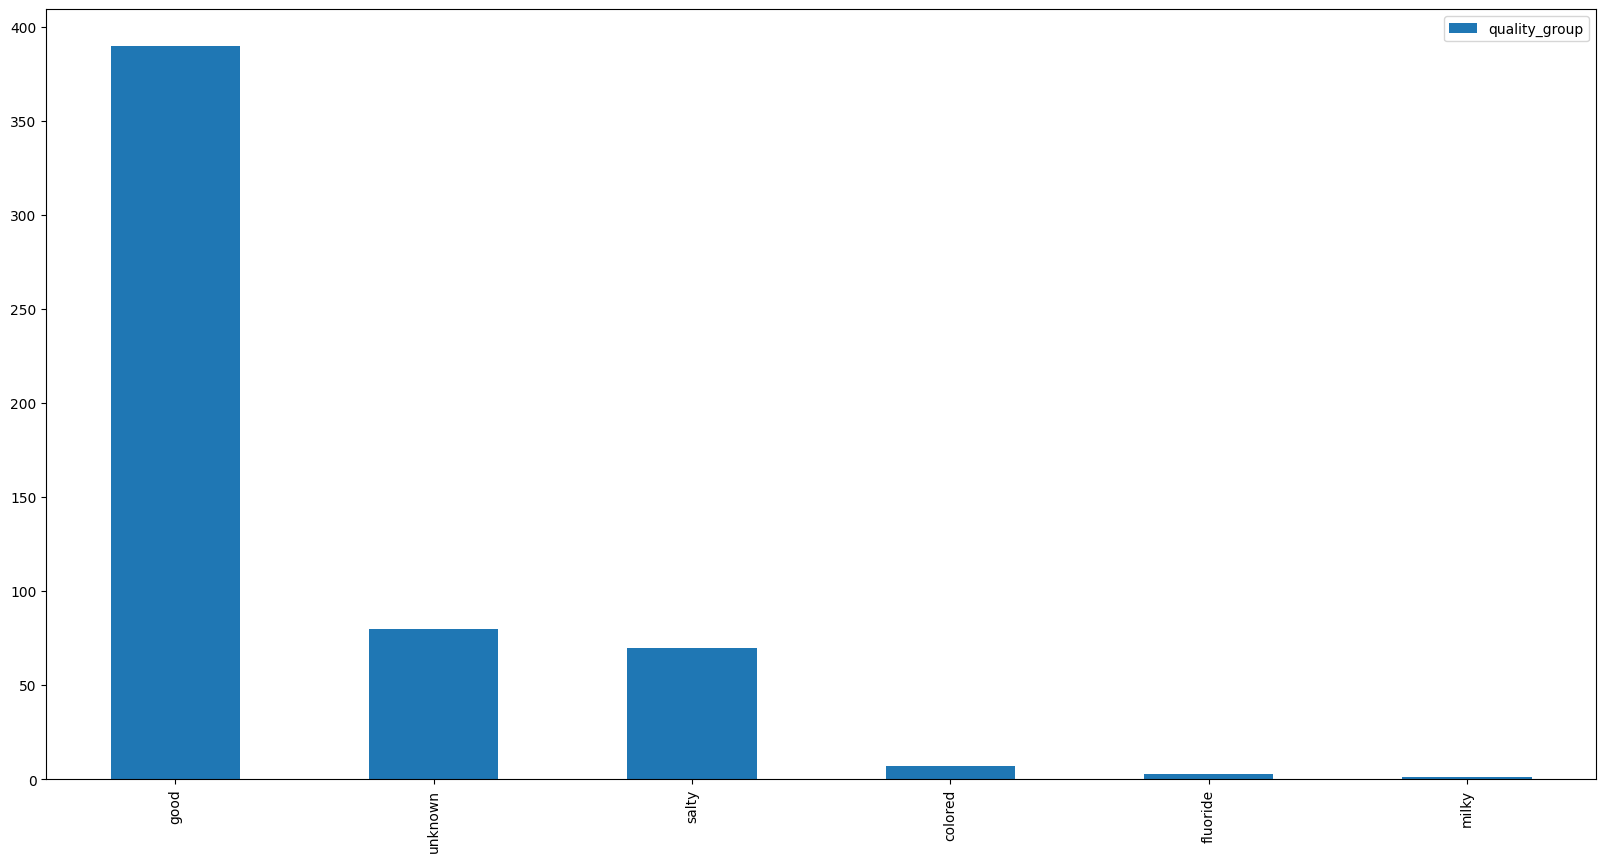

In [104]:
pd.DataFrame(nulos_lon['quality_group'].value_counts()).plot(kind = 'bar',figsize = (20,10))

In [105]:
df['region'].value_counts()

Iringa           5171
Mbeya            4135
Kilimanjaro      4057
Shinyanga        3953
Morogoro         3686
Arusha           3175
Kagera           3011
Pwani            2599
Ruvuma           2476
Tanga            2474
Mwanza           2438
Kigoma           2213
Dodoma           1992
Singida          1965
Tabora           1914
Mara             1909
Rukwa            1673
Mtwara           1604
Manyara          1487
Lindi            1453
Dar es Salaam     802
Name: region, dtype: int64